# 03 Results: three rule-based detectors

Week 3 of *meter-trust*. Three detectors label every customer meter at every 15-minute step with one of the five classes:

1. **WLS + chi-square + LNR**: the textbook baseline. A chi-square alarm, then the largest normalised residual names one meter as bad data (`meter_fault`).
2. **Peer check**: what Etrack did. Predict each customer from the 5 customers it historically tracks; a sustained deviation is a `meter_fault`.
3. **Peer check + energy balance**: same deviation signal, but ask the trusted transformer meter. Balance holds: `load_change`. Balance broken: `meter_fault` if the meter reads low, `attack` if it reads high.

All three mark a reading that did not arrive fresh as `comm_loss`. Peer and balance models are fitted on 21 days of normal history only, with thresholds set at the 99.5th percentile of that history; no labels are used anywhere. The rules are in `src/detectors.py`.

**Change since Week 2.** SimBench gives this feeder only 10 load profiles for 41 customers, so 38 customers were exact scaled copies of another customer. That would make the peer check look far better than it could be on real meters. Each customer now has its own smooth random variation (30 % std, about 1 hour memory; `grid.get_profiles`), and the power flow and the dataset were regenerated.

In [1]:
import sys
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import logging; logging.getLogger("pandapower").setLevel(logging.ERROR)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "figures"
import numpy as np, pandas as pd
pd.set_option("display.precision", 3)
import scenarios as sc, detectors as det, evaluate as ev, grid

In [2]:
# Regenerate anything missing: the scenario dataset (~1 min), then the WLS baseline (~6 min on 8 cores).
if not (sc.OUT_DIR / "labels.parquet").exists():
    sc.save(sc.generate())
data = sc.load()
wls_file = det.OUT_DIR / "wls.parquet"
if wls_file.exists():
    wls = pd.read_parquet(wls_file)
else:
    wls = det.run_wls_baseline(data)
    det.OUT_DIR.mkdir(parents=True, exist_ok=True); wls.to_parquet(wls_file)
out = det.run_all(data, wls=wls)
E, L = data["episodes"], data["labels"]
normal = wls.loc[E.index[E.cls == "normal"]]
net = grid.load_net()
dof = len(data["defs"]) + 2 * len(det.est.zero_injection_buses(net)) - (2 * len(net.bus) - 1)
print(f"WLS on normal episodes: mean J {normal.J.mean():.2f} (dof {dof}), "
      f"chi-square alarm rate {normal.flag.mean():.3f} (nominal 0.05)")

WLS on normal episodes: mean J 4.96 (dof 5), chi-square alarm rate 0.049 (nominal 0.05)


## Confusion matrices (meter-steps, all 300 episodes)

Rows are the truth, columns the detector's answer, each row normalised to 1. Most meter-steps are `normal`, so the rows for the four event classes are what matter. **The key cells are `attack` vs `load_change`.**

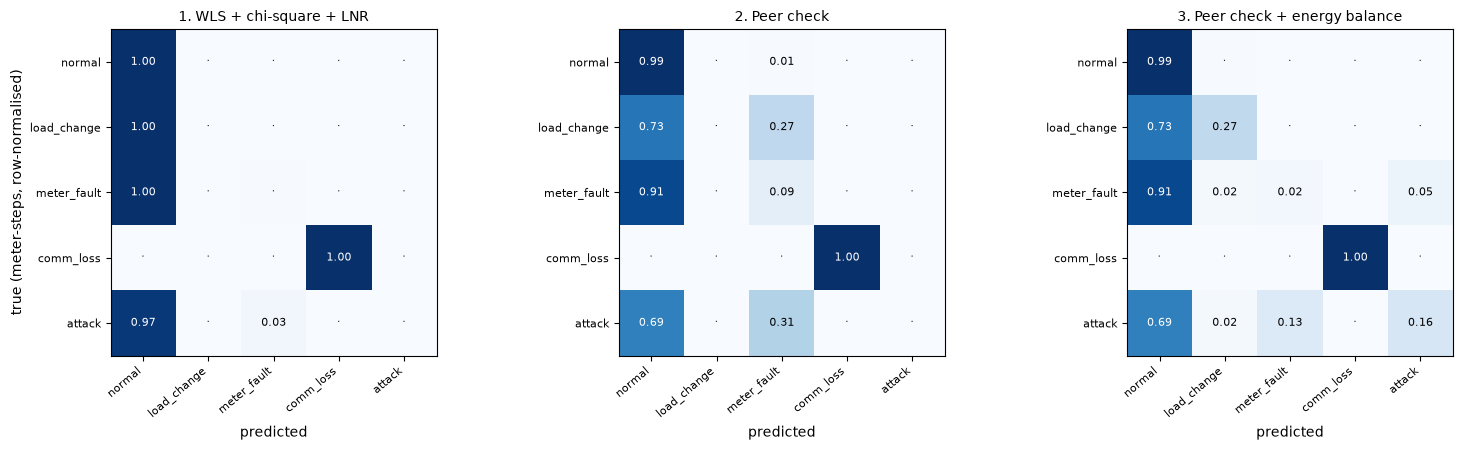

In [3]:
cms = {k: ev.confusion(L, p) for k, p in out["pred"].items()}
ev.plot_confusions(cms, FIG / "confusion_matrices.png");

In [4]:
tab = pd.concat({ev.NAMES[k]: ev.per_class(cm)[["precision", "recall"]] for k, cm in cms.items()}, axis=1)
tab.loc["false alarms (normal meter-steps)"] = [x for k, p in out["pred"].items()
                                                for x in (np.nan, ev.false_alarm_rate(L, p))]
tab

1. WLS + chi-square + LNR         \
                                                  precision recall   
true                                                                 
normal                                                0.992  0.999   
load_change                                             NaN  0.000   
meter_fault                                           0.008  0.004   
comm_loss                                             1.000  1.000   
attack                                                  NaN  0.000   
false alarms (normal meter-steps)                       NaN  0.001   

                                  2. Peer check         \
                                      precision recall   
true                                                     
normal                                    0.993  0.994   
load_change                                 NaN  0.000   
meter_fault                               0.031  0.095   
comm_loss                                 1.000  1.000   
attack                                      NaN  0.000   
false alarms (normal meter-steps)           NaN  0.006   

                                  3. Peer check + energy balance         
                                                       precision recall  
true                                                                     
normal                                                     0.993  0.994  
load_change                                                0.118  0.265  
meter_fault                                                0.065  0.024  
comm_loss                                                  1.000  1.000  
attack                                                     0.362  0.161  
false alarms (normal meter-steps)                            NaN  0.006

## Per event: detected at all, and how fast

`detected`: share of events where an affected meter was ever given the right class. `delay`: median steps (15 min) from event start to that first correct answer. `any alarm`: share where an affected meter was ever given *any* non-normal class.

In [5]:
dets = {k: ev.detection(E, p) for k, p in out["pred"].items()}
pd.concat({ev.NAMES[k]: ev.detection_summary(d)[["detected", "median delay (steps)", "any alarm"]]
           for k, d in dets.items()}, axis=1)

1. WLS + chi-square + LNR                       \
                                        detected median delay (steps)   
cls         subtype                                                     
attack      consistent                      0.00                  NaN   
            naive                           0.00                  NaN   
comm_loss   dropout                         1.00                  0.0   
            gateway                         1.00                  0.0   
            stale                           1.00                  0.0   
load_change down                            0.00                  NaN   
            up                              0.00                  NaN   
meter_fault drift                           0.05                 16.0   
            gain                            0.05                  2.0   
            stuck                           0.00                  NaN   

                                 2. Peer check                                 \
                       any alarm      detected median delay (steps) any alarm   
cls         subtype                                                             
attack      consistent      0.63          0.00                  NaN      0.60   
            naive           0.17          0.00                  NaN      0.67   
comm_loss   dropout         1.00          1.00                  0.0      1.00   
            gateway         1.00          1.00                  0.0      1.00   
            stale           1.00          1.00                  0.0      1.00   
load_change down            0.03          0.00                  NaN      0.55   
            up              0.00          0.00                  NaN      0.81   
meter_fault drift           0.05          0.00                  NaN      0.00   
            gain            0.05          0.30                 21.5      0.30   
            stuck           0.00          0.75                 25.0      0.75   

                       3. Peer check + energy balance                       \
                                             detected median delay (steps)   
cls         subtype                                                          
attack      consistent                           0.50                  6.0   
            naive                                0.27                  4.5   
comm_loss   dropout                              1.00                  0.0   
            gateway                              1.00                  0.0   
            stale                                1.00                  0.0   
load_change down                                 0.55                  7.5   
            up                                   0.81                  7.0   
meter_fault drift                                0.00                  NaN   
            gain                                 0.20                 31.0   
            stuck                                0.30                 32.0   

                                  
                       any alarm  
cls         subtype               
attack      consistent      0.60  
            naive           0.67  
comm_loss   dropout         1.00  
            gateway         1.00  
            stale           1.00  
load_change down            0.55  
            up              0.81  
meter_fault drift           0.00  
            gain            0.30  
            stuck           0.75

The same table on the **test weeks only** (days 21-27; 75 episodes). The detectors never saw labels, so this mainly checks that nothing depends on the history overlapping the training days:

In [6]:
pd.concat({ev.NAMES[k]: d[d.split == "test"].groupby("cls").detected.mean()
           for k, d in dets.items()}, axis=1).round(2)

,1. WLS + chi-square + LNR,2. Peer check,3. Peer check + energy balance
cls,,,
attack,0.00,0.0,0.50
comm_loss,1.00,1.0,1.00
load_change,0.00,0.0,0.71
meter_fault,0.07,0.4,0.27


## Consistent attack: residual test vs energy balance

Feeder-level alarms on every consistent-attack step, grouped by how large the faked change at the target meter is. The dotted lines are the same alarms on real load changes, i.e. the false-alarm level for the case the attack imitates.

,steps,chi2,balance
size,,,
"[0.0, 0.25)",433,0.05,0.06
"[0.25, 0.5)",249,0.08,0.23
"[0.5, 1.0)",251,0.29,0.67
"[1.0, 2.0)",221,0.66,0.87
"[2.0, 4.0)",149,0.98,0.96
"[4.0, inf)",77,1.00,1.00


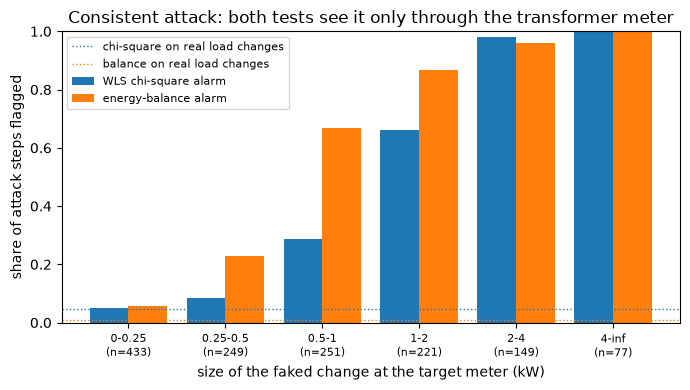

In [7]:
size = ev.attack_size_table(data, out)
ref = ev.reference_rates(data, out)
ev.plot_attack_size(size, ref, FIG / "attack_size.png")
size.round(2)

## Peer check during a gateway outage

For each healthy meter (not hit by the event): are all 5 of its peers still reporting? When one gateway fails, every meter that relies on peers behind it loses its reference, including meters behind other gateways.

,count,mean,min
case,,,
dropout,20,0.87,0.79
gateway,20,0.73,0.46
normal,60,1.00,1.00
stale,20,0.87,0.76


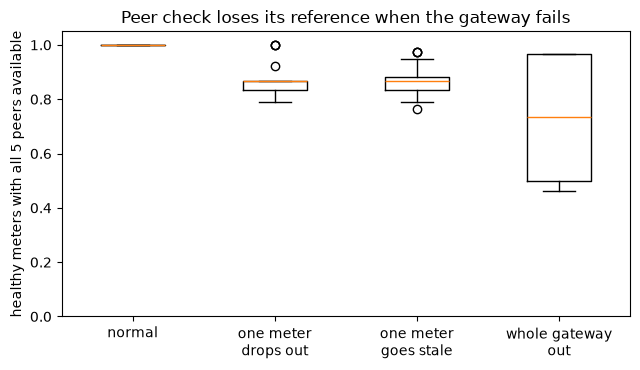

In [8]:
cov = ev.peer_coverage(data, out)
ev.plot_peer_coverage(cov, FIG / "peer_coverage.png")
cov.groupby("case").coverage.agg(["count", "mean", "min"]).round(2)

## What the results say

**Baseline (WLS).** On clean data the chi-square test behaves as theory says (mean J about 5 for 5 degrees of freedom, about 5 % alarms). But it cannot name the meter. Every customer P reading is cross-checked by exactly one other measurement, the transformer, so all customer readings sit in one *critical set*: their normalised residuals are equal and LNR picks one essentially at random. Meter-fault recall is close to zero. The baseline never answers `load_change` or `attack` because it has no such concept.

**Peer check.** It catches stuck meters most of the time and gain faults sometimes. It also flags real load changes as meter faults in most load-change events, which is the Etrack problem in numbers: a customer who really changed looks exactly like a meter that lies. Drifting meters (gain sliding to 0.6-0.8 over hours) mostly slip under its threshold, because 30 % customer-to-customer variation is a lot of noise to beat.

**Peer check + energy balance.** Asking the transformer turns most of those false meter-fault calls into correct `load_change` answers, and labels about half the consistent attacks correctly. The other half are downward attacks, which the rule cannot tell from an undercounting meter, so they land in `meter_fault`. That is an honest limit of a sign rule, not of the balance itself.

**The consistent attack (correction to the plan).** The plan expected the residual test to be blind to it. It is not: both the chi-square test and the energy balance see the attack, and both see it **only through the transformer meter**. Neither notices faked changes below about 0.25 kW. Both catch almost everything above 2 kW. In between the balance is more sensitive, mainly because it averages over 2 hours while the chi-square test looks at one step. It also stays quieter on real load changes (under 1 % against 5 %). If the attacker could also edit the transformer reading, every reading would match a real load change and neither test, nor any test on these measurements, could tell them apart. Only timing or outside information could.

**Gateway outage.** Missing readings are trivial to flag. The real damage is to the peer check: during a gateway outage only about three quarters of the *healthy* meters still have all their peers, and in the worst case less than half. A fault elsewhere on the feeder at that moment would be harder to see.

**Limits.** Meter-step recall is low for every detector because events start in the middle of a rolling window and the thresholds are deliberately strict (99.5th percentile of normal history). Counts are small: 20-30 events per subtype, 7 per attack subtype in the test weeks. All of this is simulation on a public feeder with synthetic customer variation, not utility data.